# 4. Screenplays: do hit and flop scripts differ beyond genre, era and budget?

**Question.** Do hit scripts resemble each other, and flop scripts each other, more than a hit resembles a flop?

**Method.** A hit is in the top quarter of return within genre and era, a flop in the bottom quarter. Dialogue and scene description each become one vector (the TF-IDF-weighted mean of Word2Vec vectors, 5 seeds). Resemblance is cosine similarity. The gap is the mean similarity within hits and within flops minus that between them.

**Compared to what?** 2,000 shuffles of the labels, only between films of the same genre, era and budget third. Holm correction over 18 tests.

**What it misses.** Plot and order, budget differences inside a group, films without a script, films under 10,000 votes. Groups are small, so a test that doesn't pass isn't evidence of no difference.

**How we chose it.** This test is exploratory. A planned test came first (the last section here), and its baseline used votes, which come after release. The criteria are D29 in `src/analysis/screenplays/DECISIONS.md`, written after a one-seed run and before the five-seed run.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").exists())
A = ROOT / "src" / "analysis"
pd.set_option("display.max_colwidth", 90)
W = A / 'screenplays/word2vec/results'

## The 18 tests

In [2]:
b = pd.read_csv(W / "budget_matched.csv")
b[b.shuffle_within == "era x budget terciles"].drop(columns="shuffle_within").sort_values("p").round(4)

,genre,layer,hits,flops,share_movable,separation,null_mean,null_q95,z,p,p_holm
47,Horror,description,52,52,0.9038,0.0586,0.0065,0.0246,5.6087,0.0005,0.0090
46,Horror,dialogue,52,52,0.9038,0.0485,0.0059,0.0239,4.5511,0.0010,0.0170
40,Comedy,dialogue,136,136,1.0000,0.0083,-0.0001,0.0046,3.4205,0.0075,0.1199
49,Mystery,description,50,50,0.9700,0.0245,0.0002,0.0134,3.4569,0.0105,0.1574
48,Mystery,dialogue,50,50,0.9700,0.0159,0.0013,0.0154,1.8746,0.0470,0.6577
44,Drama,dialogue,223,223,0.9955,0.0034,0.0001,0.0038,1.7541,0.0620,0.8056
41,Comedy,description,136,136,1.0000,0.0041,-0.0000,0.0047,1.6621,0.0670,0.8056
43,Crime,description,85,85,0.9412,0.0058,0.0001,0.0071,1.4618,0.0850,0.9345
36,Action,dialogue,108,108,0.9861,0.0183,0.0089,0.0221,1.3293,0.0960,0.9595
53,Thriller,description,74,74,0.9662,0.0050,-0.0007,0.0085,1.1726,0.1209,1.0000


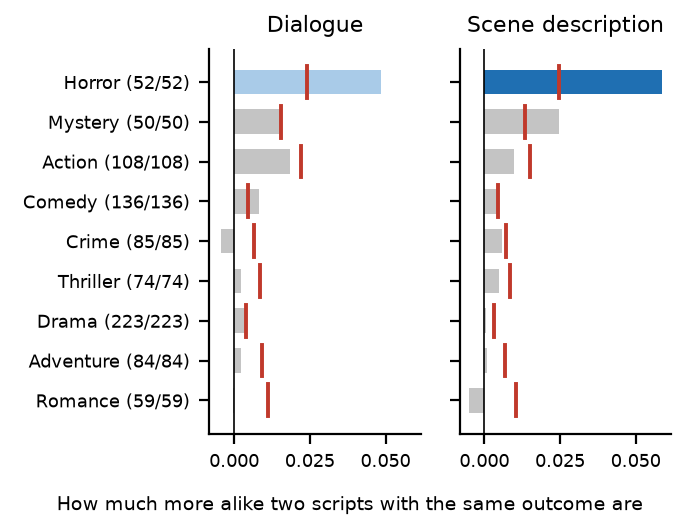

In [3]:
from IPython.display import Image
Image(str(A / "screenplays/figures/fig_script_similarity.png"), width=520)

Dark blue passes with budget thirds, halves and quarters. Light blue passes with thirds and halves only. Red: 95% of shuffles lie below.

## Does the choice of budget groups matter?

Holm p for each grouping. `era only` doesn't hold budget fixed.

In [4]:
b.assign(test=b.genre + " " + b.layer).pivot(index="test", columns="shuffle_within", values="p_holm").sort_values("era x budget terciles").round(3)

shuffle_within,era only,era x budget halves,era x budget quarters,era x budget terciles
test,,,,
Horror description,0.009,0.009,0.027,0.009
Horror dialogue,0.009,0.017,0.051,0.017
Comedy dialogue,0.082,0.082,0.142,0.120
Mystery description,0.082,0.032,0.072,0.157
Mystery dialogue,0.378,0.441,0.364,0.658
Comedy description,0.590,0.767,1.000,0.806
Drama dialogue,0.539,0.767,0.845,0.806
Crime description,0.765,0.845,0.978,0.935
Action dialogue,0.048,0.767,1.000,0.960


## Checks on Horror, the only genre that passes

`share_movable` is the share of films in groups where the shuffle can change anything.

In [5]:
pd.read_csv(W / "budget_matched_checks.csv").round(4)

,genre,check,layer,hits,flops,share_movable,separation,null_mean,null_q95,z,p,too_small
0,Horror,no franchise,dialogue,37,45,0.9390,0.0224,-0.0032,0.0127,3.2041,0.0070,False
1,Horror,no franchise,description,37,45,0.9390,0.0412,0.0008,0.0197,3.9235,0.0045,False
2,Horror,100k+ only,dialogue,46,20,0.7273,0.0475,0.0171,0.0532,1.5016,0.0775,False
3,Horror,100k+ only,description,46,20,0.7273,0.0307,-0.0002,0.0287,1.8266,0.0415,False
4,Horror,terciles x vote tier,dialogue,52,52,0.5769,0.0485,0.0169,0.0332,3.4148,0.0055,False
5,Horror,terciles x vote tier,description,52,52,0.5769,0.0586,0.0223,0.0440,2.9837,0.0075,False
6,Horror,"main, vectors_w5_s1 alone",dialogue,52,52,0.9038,0.0490,0.0059,0.0237,4.6093,0.0005,False
7,Horror,"main, vectors_w5_s1 alone",description,52,52,0.9038,0.0582,0.0064,0.0243,5.6019,0.0005,False
8,Horror,"main, vectors_w5_s2 alone",dialogue,52,52,0.9038,0.0492,0.0060,0.0241,4.5644,0.0010,False
9,Horror,"main, vectors_w5_s2 alone",description,52,52,0.9038,0.0594,0.0066,0.0247,5.6082,0.0005,False


## Which words differ?

Log-odds words with labels shuffled within era and budget third. `family_p` corrects for testing every word.

In [6]:
w = pd.read_csv(W / "budget_matched_words.csv")
w.groupby("layer").head(8)[["layer", "word", "direction", "calibrated_z", "family_p", "hit_films", "flop_films"]].round(3)

,layer,word,direction,calibrated_z,family_p,hit_films,flop_films
0,dialogue,hello,hit,3.466,0.287,45,44
1,dialogue,usually,hit,3.125,0.832,23,13
2,dialogue,show,flop,-3.109,0.847,42,46
3,dialogue,shot,flop,-3.084,0.872,29,36
4,dialogue,practice,hit,3.000,0.942,14,4
5,dialogue,squad,flop,-2.931,0.976,2,9
6,dialogue,dirt,flop,-2.921,0.982,2,13
7,dialogue,hearts,hit,2.920,0.982,13,3
20,description,closet,hit,4.085,0.021,39,19
21,description,choke,flop,-3.546,0.363,5,18


## The planned test, for comparison

A cross-validated classifier (AUC; 0.5 is guessing). `tier+era+genres` contains whether a film has 100,000+ votes. The last model adds the vector to facts known before release. We don't interpret the Action gain, because the similarity test doesn't support it.

In [7]:
pd.read_csv(W / "prerelease_auc.csv").round(3)

,genre,layer,model,n,seeds,auc,gain,lo,hi
0,Comedy,-,tier+era+genres,272,0,0.782,NaN,NaN,NaN
1,Comedy,-,era+genres,272,0,0.552,NaN,NaN,NaN
2,Comedy,-,era+genres+budget,272,0,0.542,NaN,NaN,NaN
3,Comedy,dialogue,vector,272,5,0.613,NaN,NaN,NaN
4,Comedy,dialogue,era+genres+budget + vector,272,5,0.572,0.030,-0.034,0.090
5,Comedy,description,vector,272,5,0.583,NaN,NaN,NaN
6,Comedy,description,era+genres+budget + vector,272,5,0.560,0.018,-0.036,0.070
7,Action,-,tier+era+genres,216,0,0.706,NaN,NaN,NaN
8,Action,-,era+genres,216,0,0.532,NaN,NaN,NaN
9,Action,-,era+genres+budget,216,0,0.537,NaN,NaN,NaN
